In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import os
from tensorflow.keras.models import load_model
from tensorflow.keras.datasets import cifar10

# 1. Define paths and CIFAR-10 labels
MODEL_PATH = os.path.join('results', 'best_model.keras')

# CIFAR-10 official class names mapped to their indices
labels = {
    0: 'Airplane', 1: 'Automobile', 2: 'Bird', 3: 'Cat',
    4: 'Deer', 5: 'Dog', 6: 'Frog', 7: 'Horse',
    8: 'Ship', 9: 'Truck'
}

# 2. Load the dataset
print("Loading CIFAR-10 dataset...")
(_, _), (x_test, y_test) = cifar10.load_data()

# Flatten y_test from shape (10000, 1) to (10000,) for easier indexing
Y_true = y_test.flatten()

# 3. Preprocess the test data
print("Preprocessing test data...")
x_test_processed = x_test.astype('float32') / 255.0

# 4. Load the model and make predictions
print(f"Loading model from {MODEL_PATH}...")
model = load_model(MODEL_PATH)

print("Generating predictions...")
predictions = model.predict(x_test_processed)

# Convert predicted probabilities into class indices (0 to 9)
Y_pred_classes = np.argmax(predictions, axis=1)

# 5. Define the visualization function
def show_test(number):
    fig = plt.figure(figsize=(4, 4))
    
    # Get the predicted class index
    dict_key = Y_pred_classes[number]
    
    # Show the original, un-normalized image
    plt.imshow(x_test[number])
    
    # Add title with predicted vs true labels
    plt.title(f"Predicted: {labels[dict_key]}\nTrue Label: {labels[Y_true[number]]}")
    plt.axis('off')
    plt.show()

# 6. Test the function with image 20 (which is a horse)
print("\nDisplaying test image 20...")

Loading CIFAR-10 dataset...
Preprocessing test data...
Loading model from results\best_model.keras...
Generating predictions...
313/313 ━━━━━━━━━━━━━━━━━━━━ 7s 23ms/step

Displaying test image 20...


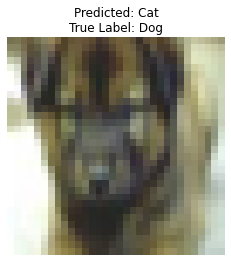

In [ ]:
show_test(31)